# One Cape Cauldron vortex

This notebook takes one of the vortices that `cape_cauldron_vortices` finds,
the counter-clockwise one near 5.2 degrees E and 30.6 degrees S, and looks at
it closely. It shows the whole family of closed orbits found at its centre,
why `outermost_shear_lines` picks the one it does, and how the boundary sits
in the Cauchy–Green anisotropy, the FTLE and the polar rotation angle. The
Parcels setup is the one of `cape_cauldron_vortices`.

In [1]:
# Importing Parcels pulls in the holoviews/bokeh bootstrap and prints an
# alpha-version notice, neither of which belongs on the rendered page.
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from parcels import FieldSet, Particle, ParticleSet, StatusCode
from parcels.convert import copernicusmarine_to_sgrid
from parcels.kernels import AdvectionRK4

from lcs_parcels import (
    NeighborSeedGrid,
    closed_shear_lines,
    elliptic_centres,
    outermost_shear_lines,
    rotation_sense,
    stretch_range,
)

/var/folders/w1/m9mm9h9167z_gcfzfffr0rgsh6j6kj/T/ipykernel_69605/762595560.py:6: UserWarning: This is an alpha version of Parcels v4. The API is not stable and may change without deprecation warnings.
  from parcels import FieldSet, Particle, ParticleSet, StatusCode


## Currents and field set

The daily-mean GLORYS12 surface currents of `cape_cauldron_vortices`.

In [2]:
currents = xr.open_dataset("data/cape_cauldron_glorys_daily.nc").load()
sgrid = copernicusmarine_to_sgrid(fields={"U": currents["uo"], "V": currents["vo"]})
fieldset = FieldSet.from_sgrid_conventions(sgrid, mesh="spherical")
z_surface = float(currents["depth"].values[0])

## Seed grid and window

A box of 4 degrees centred on the eddy keeps its boundary well inside the
flow map and clear of the 50 km edge margin of `elliptic_centres`. The
spacing is 1/50 degree, twice as fine as in `cape_cauldron_vortices` with a
fifth of its particles. `closed_shear_lines` launches at the grid spacing, so
the finer grid also gives a denser family of orbits. Release and window are
unchanged.

In [3]:
t0 = np.datetime64("2018-06-01")
T = np.timedelta64(15, "D")
lon_axis = np.arange(3.2, 7.2 + 1e-9, 1 / 50)
lat_axis = np.arange(-32.6, -28.6 + 1e-9, 1 / 50)
seed = NeighborSeedGrid.from_axes(lon=lon_axis, lat=lat_axis)
seed

<NeighborSeedGrid 201x201 grid, lon 3.20..7.20, lat -32.60..-28.60>

## Recovery kernel

Lost particles become `NaN` in place, as in `cape_cauldron_vortices`.

In [4]:
def set_lost_to_nan(particles, fieldset):
    lost = particles.state >= StatusCode.Error
    particles.x = np.where(lost, np.nan, particles.x)
    particles.y = np.where(lost, np.nan, particles.y)
    particles.state = np.where(lost, StatusCode.EndofLoop, particles.state)

## Advect forward

In [5]:
lon, lat = seed.to_parcels_pset()
z = np.full(len(lon), z_surface)
pset = ParticleSet(fieldset, pclass=Particle, x=lon, y=lat, z=z, t=t0)
pset.execute(
    [AdvectionRK4, set_lost_to_nan],
    dt=np.timedelta64(1, "h"),
    runtime=T,
    verbose_progress=False,
)
forward = seed.pset_to_flowmap(lon=pset.x, lat=pset.y, t0=t0, t1=t0 + T)
forward

<NeighborFlowMap 201x201 grid, lon 3.20..7.20, lat -32.60..-28.60,
                 t0 2018-06-01T00:00:00, T +15.0 days>

The first day, for the polar rotation angle.

In [6]:
pset_day = ParticleSet(fieldset, pclass=Particle, x=lon, y=lat, z=z, t=t0)
pset_day.execute(
    [AdvectionRK4, set_lost_to_nan],
    dt=np.timedelta64(1, "h"),
    runtime=np.timedelta64(1, "D"),
    verbose_progress=False,
)
first_day = seed.pset_to_flowmap(
    lon=pset_day.x, lat=pset_day.y, t0=t0, t1=t0 + np.timedelta64(1, "D")
)

## The centre

`elliptic_centres` on the box, then the candidate nearest 5.2 degrees E and
30.6 degrees S. `isel` with a list keeps the `centre` dim, so the one centre
goes into `closed_shear_lines` like a list of them.

In [7]:
anisotropy = forward.cg_anisotropy()
centres = elliptic_centres(anisotropy, extremum="min", window_m=100_000.0)
centres

<xarray.Dataset> Size: 144B
Dimensions:  (centre: 6)
Coordinates:
  * centre   (centre) int64 48B 0 1 2 3 4 5
Data variables:
    lon      (centre) float64 48B 5.08 5.08 5.7 5.76 6.04 6.36
    lat      (centre) float64 48B -30.82 -29.16 -31.52 -32.02 -29.4 -31.56
Attributes:
    extremum:          min
    edge_m:            50000.0
    edge_cells_i:      27
    edge_cells_j:      23
    window_m:          100000.0
    window_cells_i:    51
    window_cells_j:    45
    grid_spacing_i_m:  1914.202931051854
    grid_spacing_j_m:  2223.8985328915223

In [8]:
distance = np.hypot(centres["lon"] - 5.2, centres["lat"] + 30.6)
centre = centres.sortby(distance).isel(centre=[0])
centre

<xarray.Dataset> Size: 24B
Dimensions:  (centre: 1)
Coordinates:
  * centre   (centre) int64 8B 0
Data variables:
    lon      (centre) float64 8B 5.08
    lat      (centre) float64 8B -30.82
Attributes:
    extremum:          min
    edge_m:            50000.0
    edge_cells_i:      27
    edge_cells_j:      23
    window_m:          100000.0
    window_cells_i:    51
    window_cells_j:    45
    grid_spacing_i_m:  1914.202931051854
    grid_spacing_j_m:  2223.8985328915223

## Every closed orbit at the centre

In [9]:
orbits = closed_shear_lines(
    forward,
    centre_lon=centre["lon"],
    centre_lat=centre["lat"],
    stretches=stretch_range(stretch_max=1.5, step=0.03),
)
orbits

<xarray.Dataset> Size: 724kB
Dimensions:       (orbit: 73, point: 610)
Coordinates:
  * orbit         (orbit) int64 584B 0 1 2 3 4 5 6 7 ... 65 66 67 68 69 70 71 72
  * point         (point) int64 5kB 0 1 2 3 4 5 6 ... 604 605 606 607 608 609
Data variables: (12/13)
    lon           (orbit, point) float64 356kB 6.082 6.079 6.076 ... nan nan nan
    lat           (orbit, point) float64 356kB -30.82 -30.81 -30.8 ... nan nan
    centre_index  (orbit) int64 584B 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    centre_lon    (orbit) float64 584B 5.08 5.08 5.08 5.08 ... 5.08 5.08 5.08
    centre_lat    (orbit) float64 584B -30.82 -30.82 -30.82 ... -30.82 -30.82
    stretch       (orbit) float64 584B 0.9139 0.9139 0.9139 ... 1.03 1.03 1.03
    ...            ...
    area_m2       (orbit) float64 584B 2.258e+10 2.305e+10 ... 1.807e+09
    radius_m      (orbit) float64 584B 8.477e+04 8.565e+04 ... 2.398e+04
    centroid_lon  (orbit) float64 584B 5.207 5.209 5.212 ... 5.038 5.05 5.063
    centroid_lat  (orbit) float64 584B -30.58 -30.58 -30.58 ... -30.63 -30.62
    residual_m    (orbit) float64 584B 174.4 647.8 771.9 ... 570.5 94.44 309.0
    at_scan_edge  (orbit) bool 73B False False False False ... False False False
Attributes:
    stretch_min:       0.6770568744981647
    stretch_max:       1.4769807938826427
    n_stretch:         27
    max_radius_m:      150000.0
    launch_spacing_m:  1914.202931051854
    step_m:            957.101465525927
    closure_tol_m:     957.101465525927
    grid_spacing_m:    1914.202931051854
    n_centres:         1

The outermost orbit and its rotation sense over the first day,
counter-clockwise positive.

In [10]:
eddy = outermost_shear_lines(orbits)
eddy = rotation_sense(eddy, rotation=first_day.polar_rotation())
eddy[["stretch", "branch", "radius_m", "residual_m", "at_scan_edge"]]

<xarray.Dataset> Size: 41B
Dimensions:       (orbit: 1)
Coordinates:
  * orbit         (orbit) int64 8B 37
Data variables:
    stretch       (orbit) float64 8B 0.8869
    branch        (orbit) int64 8B 1
    radius_m      (orbit) float64 8B 8.744e+04
    residual_m    (orbit) float64 8B 612.5
    at_scan_edge  (orbit) bool 1B False
Attributes:
    stretch_min:            0.6770568744981647
    stretch_max:            1.4769807938826427
    n_stretch:              27
    max_radius_m:           150000.0
    launch_spacing_m:       1914.202931051854
    step_m:                 957.101465525927
    closure_tol_m:          957.101465525927
    grid_spacing_m:         1914.202931051854
    n_centres:              1
    n_orbits_in:            73
    n_centres_with_orbits:  1

In [11]:
eddy[["rotation_rad", "rotation_sense"]]

<xarray.Dataset> Size: 24B
Dimensions:         (orbit: 1)
Coordinates:
  * orbit           (orbit) int64 8B 37
Data variables:
    rotation_rad    (orbit) float64 8B 0.4149
    rotation_sense  (orbit) float64 8B 1.0
Attributes:
    stretch_min:            0.6770568744981647
    stretch_max:            1.4769807938826427
    n_stretch:              27
    max_radius_m:           150000.0
    launch_spacing_m:       1914.202931051854
    step_m:                 957.101465525927
    closure_tol_m:          957.101465525927
    grid_spacing_m:         1914.202931051854
    n_centres:              1
    n_orbits_in:            73
    n_centres_with_orbits:  1

## The orbit family

Each orbit coloured by its stretching factor $\lambda$, solid on the $+$
branch and dashed on the $-$ branch, over the anisotropy. The outermost
orbit is drawn in red.

In [12]:
log_anisotropy = (
    np.log10(anisotropy)
    .rename("log10_cg_anisotropy")
    .assign_attrs(long_name="log10 of the Cauchy-Green eigenvalue ratio", units="1")
)

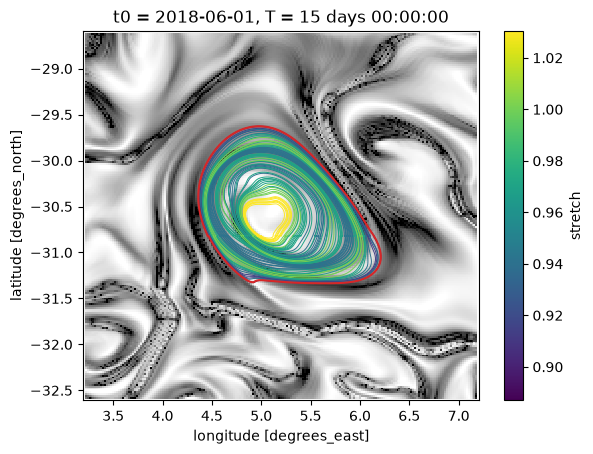

In [13]:
norm = plt.Normalize(orbits["stretch"].min(), orbits["stretch"].max())
_, ax = plt.subplots()
log_anisotropy.plot.pcolormesh(
    x="lon_grid", y="lat_grid", ax=ax, cmap="Greys", robust=True, add_colorbar=False
)
for orbit in orbits["orbit"]:
    one = orbits.sel(orbit=orbit)
    ax.plot(
        one["lon"],
        one["lat"],
        color=plt.cm.viridis(norm(one["stretch"])),
        ls="-" if one["branch"] > 0 else "--",
        lw=0.7,
    )
ax.plot(eddy["lon"].T, eddy["lat"].T, color="tab:red", lw=1.5)
plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=ax, label="stretch")
plt.show()

Equivalent radius against $\lambda$, one point per orbit, with the outermost
orbit circled. It is the orbit of largest area, wherever its $\lambda$ lies
in the scan.

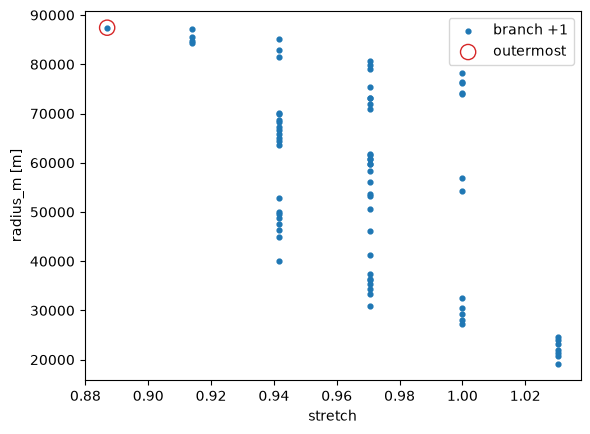

In [14]:
_, ax = plt.subplots()
for branch, group in orbits.groupby("branch"):
    ax.scatter(group["stretch"], group["radius_m"], s=12, label=f"branch {branch:+d}")
ax.scatter(
    eddy["stretch"],
    eddy["radius_m"],
    s=120,
    facecolors="none",
    edgecolors="tab:red",
    label="outermost",
)
ax.set_xlabel("stretch")
ax.set_ylabel("radius_m [m]")
ax.legend()
plt.show()

The closure residual of each orbit, against the same axis. The closure
tolerance is half the grid spacing.

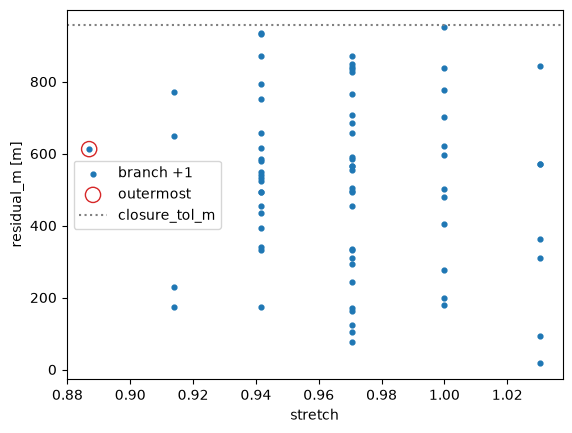

In [15]:
_, ax = plt.subplots()
for branch, group in orbits.groupby("branch"):
    ax.scatter(group["stretch"], group["residual_m"], s=12, label=f"branch {branch:+d}")
ax.scatter(
    eddy["stretch"],
    eddy["residual_m"],
    s=120,
    facecolors="none",
    edgecolors="tab:red",
    label="outermost",
)
ax.axhline(orbits.attrs["closure_tol_m"], color="grey", ls=":", label="closure_tol_m")
ax.set_xlabel("stretch")
ax.set_ylabel("residual_m [m]")
ax.legend()
plt.show()

## The fields with the boundary

The anisotropy and the FTLE over the 15-day window, and the polar rotation
angle over the first day, each with the boundary in black.

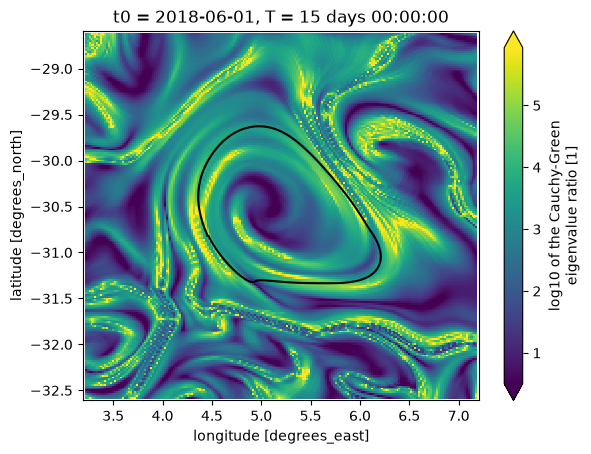

In [16]:
_, ax = plt.subplots()
log_anisotropy.plot.pcolormesh(x="lon_grid", y="lat_grid", ax=ax, robust=True)
ax.plot(eddy["lon"].T, eddy["lat"].T, color="black", lw=1.5)
plt.show()

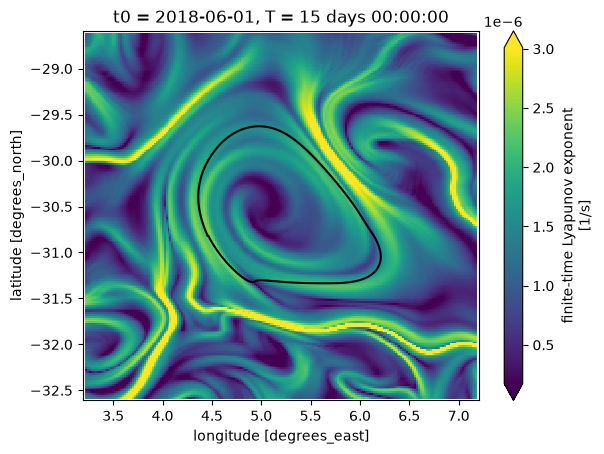

In [17]:
ftle = forward.ftle()
_, ax = plt.subplots()
ftle.plot.pcolormesh(x="lon_grid", y="lat_grid", ax=ax, robust=True)
ax.plot(eddy["lon"].T, eddy["lat"].T, color="black", lw=1.5)
plt.show()

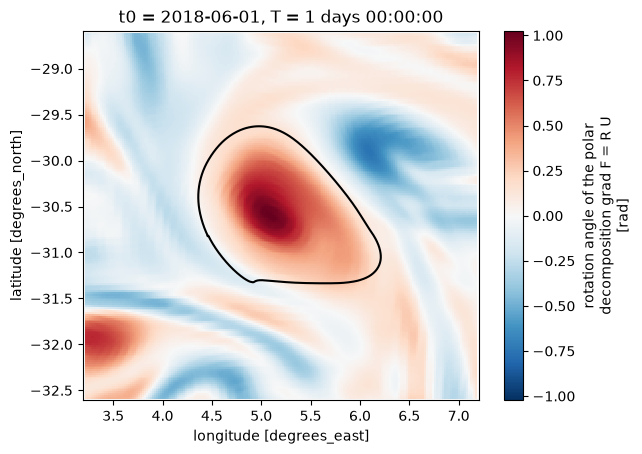

In [18]:
rotation = first_day.polar_rotation()
_, ax = plt.subplots()
rotation.plot.pcolormesh(x="lon_grid", y="lat_grid", ax=ax)
ax.plot(eddy["lon"].T, eddy["lat"].T, color="black", lw=1.5)
plt.show()

## Profiles through the centre

Each field along the grid row through the centre, with dotted lines where the
boundary crosses that latitude. The crossings are the boundary points within
0.02 degree of the centre's latitude.

In [19]:
centre_lat = float(centre["lat"].squeeze())
j_centre = int(np.abs(forward.ds["lat_grid"].isel(i=0) - centre_lat).argmin("j"))
crossings = eddy["lon"].where(np.abs(eddy["lat"] - centre_lat) < 0.02)
west, east = float(crossings.min()), float(crossings.max())
west, east

(4.451437335000451, 6.149276684670712)

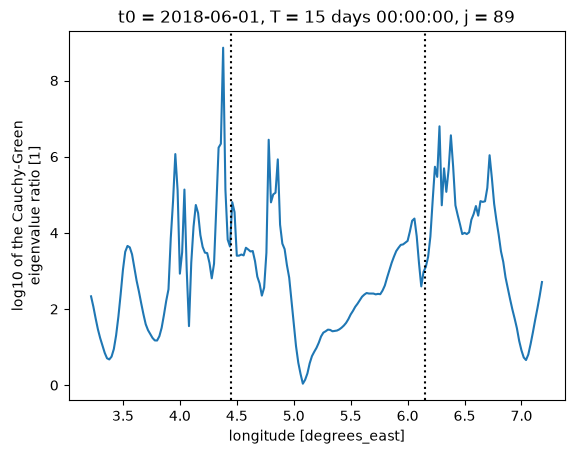

In [20]:
_, ax = plt.subplots()
log_anisotropy.isel(j=j_centre).plot(x="lon_grid", ax=ax)
ax.axvline(west, color="black", ls=":")
ax.axvline(east, color="black", ls=":")
plt.show()

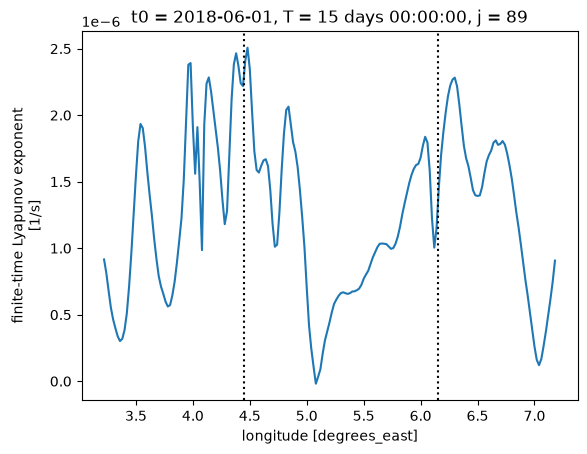

In [21]:
_, ax = plt.subplots()
ftle.isel(j=j_centre).plot(x="lon_grid", ax=ax)
ax.axvline(west, color="black", ls=":")
ax.axvline(east, color="black", ls=":")
plt.show()

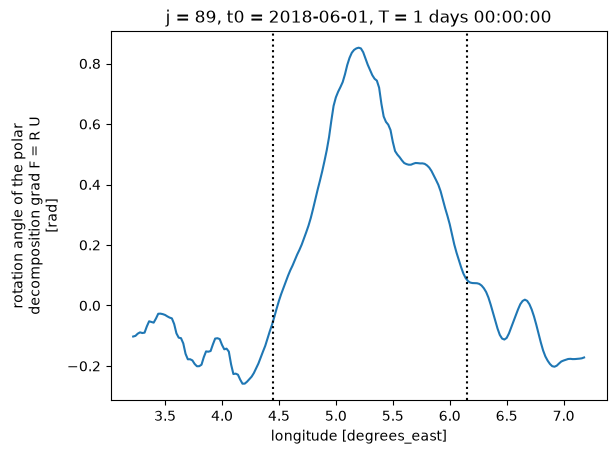

In [22]:
_, ax = plt.subplots()
rotation.isel(j=j_centre).plot(x="lon_grid", ax=ax)
ax.axvline(west, color="black", ls=":")
ax.axvline(east, color="black", ls=":")
plt.show()

## Outcome

The candidate nearest 5.2 degrees E and 30.6 degrees S is the grid point at
5.08 degrees E and 30.82 degrees S, and `closed_shear_lines` closes 73 orbits
around it, all on the $+$ branch. They span $\lambda$ from 0.887 to 1.030 and
radii from 19 km to 87 km, and the larger orbits close at the smaller
$\lambda$. The outermost orbit closes at $\lambda = 0.887$, the smallest
$\lambda$ with an orbit, with a radius of 87.4 km and a closure residual of
613 m against a tolerance of 957 m. `at_scan_edge` is False. Its centroid is at
5.21 degrees E and 30.57 degrees S, and it crosses the centre's latitude at
4.45 and 6.15 degrees E. Over the first day it turns counter-clockwise, with a
mean rotation angle of 0.41 rad and `rotation_sense` $+1$, which south of the
equator is anticyclonic.